In [32]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
from skimage import io
from glob import glob
import anndata as ad
import scanpy as sc
import seaborn as sns
import awkward as ak
import pickle
import torch

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# Add base dir to path
import sys
sys.path.insert(0, '../')

In [3]:
# Make color palette for all groups we'll come across
tmp_patterns = ["small-intestine","random", "intranuclear", "nuclear-edge", "extranuclear", "foci", "protrusion", "cell-edge", "perinuclear", 
                         "pericellular","pattern"]
def get_cmap(n, name='tab10'):
    ##Returns a function that maps each index in 0, 1, ..., n-1 to a distinct 
    ##RGB color; the keyword argument name must be a standard mpl colormap name.
    return plt.cm.get_cmap(name, n)

global_cmap = get_cmap(len(tmp_patterns))
# cmap = get_cmap(len(adata.obs["pattern"].unique()), name="tab10")
palette = {}
for i, el in enumerate(tmp_patterns):
    palette[el] =  global_cmap(i)
    
colorblind_palette = sns.color_palette("colorblind")

In [7]:
# tmp pointer to acutal data, remove before committing
simulation_dir = Path("/mnt/data/david/simulated_cells/templates/")
data_dir = Path("/mnt/data/david/subcellspace_data/")

In [8]:
# Make sure seed is the same at all times, in all packages that use it
seed = 101
torch.manual_seed(seed)
import random
random.seed(seed)
np.random.seed(seed)

In [6]:
simulation_dir = Path("/path/to/output/of/simulations/") # output of training_subcellspace/create_simulations/

In [ ]:
data_dir = Path("path/to/data/dir/")

In [9]:
subcellspace = torch.load("../SubCellSpace")

In [10]:
from src.adata_utils import convertRecordToDf, decodeSubcellEmbedding, getAllDetectedTranscripts, getXYOfSingleCell, reshape_and_filter_anndata_with_index_and_mapping
from src.plotting import plotFullDataPoint

In [11]:
single_cell_adata = ad.read_h5ad(data_dir / "apex_validation_data" / "adata_subcell_including_randomized_embeddings.h5ad")

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/anndata/_core/aligned_mapping.py:54: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(


In [12]:
single_cell_adata

AnnData object with n_obs × n_vars = 154296 × 541
    obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size'
    var: 'gene_name', 'gene_label'
    uns: 'measured_df'
    obsm: 'cell_mask', 'dapi_mask', 'detected_transcripts'
    layers: 'random_subcell_embedding', 'subcell_embedding'

In [13]:
adata = ad.read_h5ad(data_dir / "apex_validation_data" / "adata_subcell_embeddings_classified_and_subtypes.h5ad")

In [ ]:
import math
def getUnevenSubplots(num_axes):
    # Determine the grid size
    n_cols = math.ceil(math.sqrt(num_axes))
    n_rows = math.ceil(num_axes / n_cols)
    
    # Create figure
    fig = plt.figure(figsize=(8, 6))
    
    # Calculate basic sizes
    width = 0.8 / n_cols  # width of each subplot
    height = 0.8 / n_rows  # height of each subplot
    gap_x = (1 - (width * n_cols)) / (n_cols + 1)  # horizontal gap
    gap_y = (1 - (height * n_rows)) / (n_rows + 1)  # vertical gap
    
    for i in range(num_axes):
        row = i // n_cols
        col = i % n_cols
        
        # Special case: Last row has fewer elements than the rest
        if row == n_rows - 1 and num_axes % n_cols != 0:
            # Center subplots in the last row
            extra_cols = num_axes % n_cols
            col_start = (n_cols - extra_cols) / 2  # offset to center subplots
            col = i % extra_cols + col_start
            
        # Calculate position
        left = gap_x + (width + gap_x) * col
        bottom = 1 - gap_y - height - (height + gap_y) * row
        
        # Add subplot to the figure
        ax = fig.add_axes([left, bottom, width, height])
    return fig


In [21]:
# Now we exclusively explore the data that APEX-seq flagged as being localized
adata = adata[~adata.obs["apex_assigned"].isna()]
adata = adata[~(adata.obs["apex_assigned"] == "random")]

In [63]:
sc.tl.pca(adata, svd_solver='arpack', n_comps = adata.X.shape[1]-1)

In [64]:
sc.pp.neighbors(adata, n_neighbors=25)

In [435]:
sc.tl.umap(adata)

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/umap/spectral.py:342: UserWarning: Exited at iteration 20 with accuracies 
[0.00821758 0.01918104 0.01904365]
not reaching the requested tolerance 1e-08.
Use iteration 21 instead with accuracy 
0.015480755022685436.

  eigenvalues, eigenvectors = scipy.sparse.linalg.lobpcg(
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/umap/spectral.py:342: UserWarning: Exited postprocessing with accuracies 
[0.00821758 0.01918104 0.01904365]
not reaching the requested tolerance 1e-08.
  eigenvalues, eigenvectors = scipy.sparse.linalg.lobpcg(


## Fig 3A

In [ ]:
sc.tl.embedding_density(adata, basis='umap', groupby='apex_assigned')

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/__init__.py:1488: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[density_col_name] = dens_values


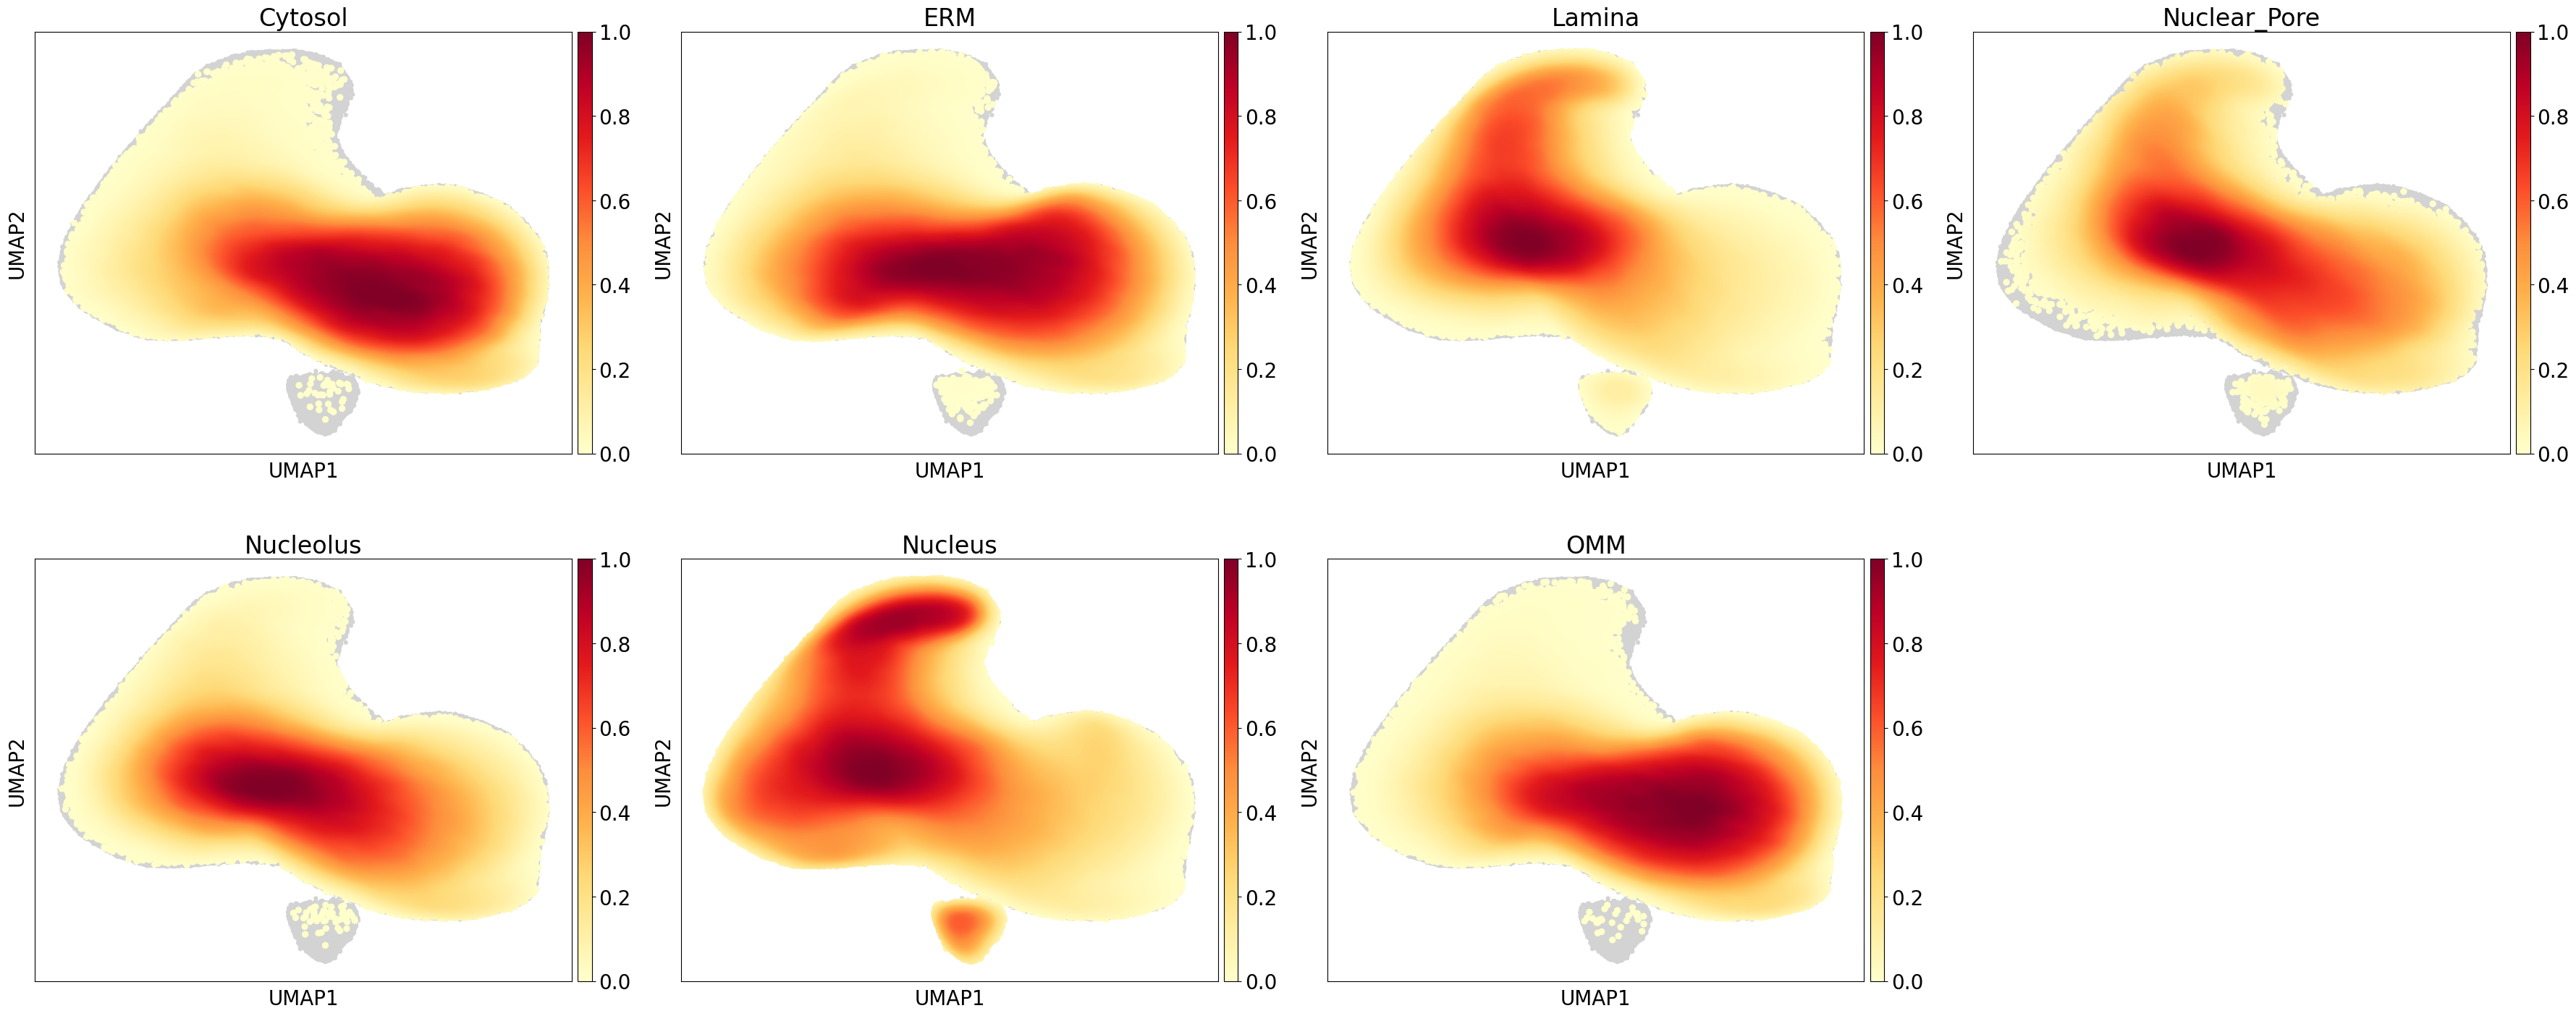

In [60]:
fig = sc.pl.embedding_density(adata[adata.obs["apex_assigned"] != "random"], basis='umap', key='umap_density_apex_assigned', return_fig=True)

## Fig 3B

(Slightly faster implementation of doing leiden clustering rather than just sc.tl.leiden)

In [65]:
adjacency = sc._utils._choose_graph(adata, neighbors_key="neighbors",obsp=None)

In [66]:
g = sc._utils.get_igraph_from_adjacency(adjacency)

In [67]:
res = 0.6

In [68]:
clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


/tmp/ipykernel_2788462/3850926258.py:1: DeprecationWarning: resolution_parameter keyword argument is deprecated, use resolution=... instead
  clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


In [69]:
adata.obs[f'leiden_igraph_res_{res}'] = pd.Series(clustering.membership,  index=adata.obs.index).astype('category')


In [41]:
# merge 0 and 1 as they seem to represent the same thing
cluster_merge_mapping = {
    0:1,
}
adata.obs[f'leiden_igraph_res_{res}'] = adata.obs[f'leiden_igraph_res_{res}'].replace(cluster_merge_mapping)

/tmp/ipykernel_3772000/334670357.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[f'leiden_igraph_res_{res}'] = adata.obs[f'leiden_igraph_res_{res}'].replace(cluster_merge_mapping)


/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


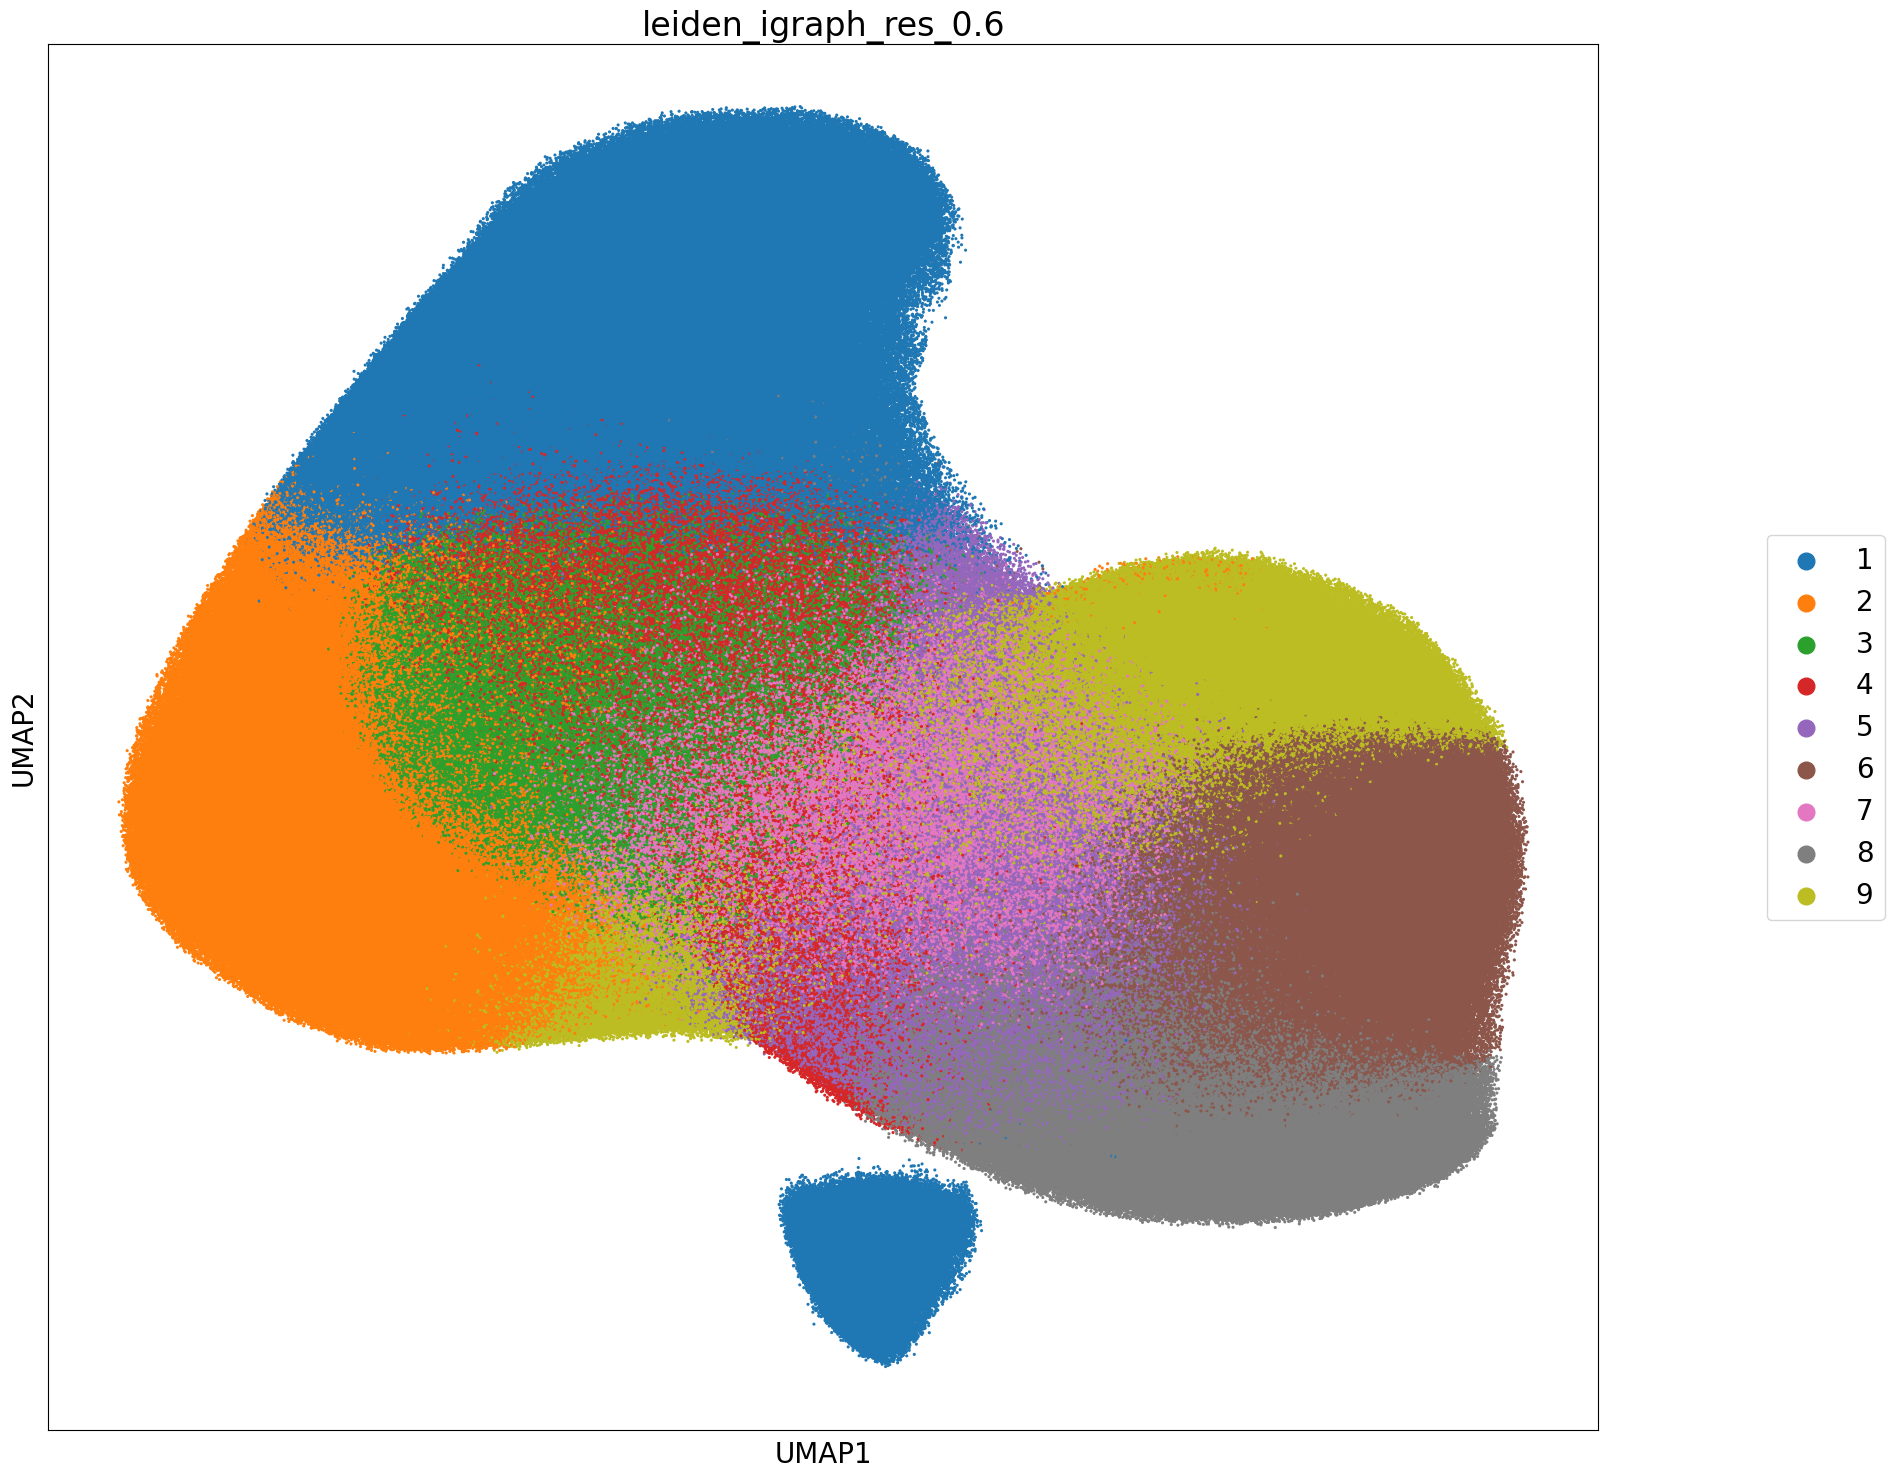

In [92]:
plt.rcParams["figure.figsize"] = [20,18]
fig = sc.pl.umap(adata, color =f'leiden_igraph_res_{res}',s=20, return_fig = True)
handles, labels = fig.gca().get_legend_handles_labels()
fig.gca().legend().remove()
fig.legend(handles, labels, fontsize = 20, markerscale=2, bbox_to_anchor=(1.05, 0.5), loc='center right')

## Fig 3C

### First interpret the clusters with mean decoding:

In [35]:
import matplotlib.pyplot as plt
import math

def create_custom_grid(num_axes):
    # Determine the grid size
    n_cols = math.ceil(math.sqrt(num_axes))
    n_rows = math.ceil(num_axes / n_cols)
    
    # Create figure
    fig = plt.figure(figsize=(8, 6))
    
    # Calculate basic sizes
    width = 0.8 / n_cols  # width of each subplot
    height = 0.8 / n_rows  # height of each subplot
    gap_x = (1 - (width * n_cols)) / (n_cols + 1)  # horizontal gap
    gap_y = (1 - (height * n_rows)) / (n_rows + 1)  # vertical gap
    
    for i in range(num_axes):
        row = i // n_cols
        col = i % n_cols
        
        # Special case: last row has fewer elements than the rest
        if row == n_rows - 1 and num_axes % n_cols != 0:
            extra_cols = num_axes % n_cols
            col_start = (n_cols - extra_cols) / 2  # offset to center subplots
            
            # Compute index *within* last row (not global i)
            index_in_row = i - row * n_cols
            col = col_start + index_in_row
            
        # Calculate position
        left = gap_x + (width + gap_x) * col
        bottom = 1 - gap_y - height - (height + gap_y) * row
        
        # Add subplot
        ax = fig.add_axes([left, bottom, width, height])
    
    return fig, fig.axes


In [36]:
from skimage.filters import gaussian
plt.rcParams["figure.figsize"] = [16, 10]

def createInputImage(adata_for_one_obs):
    empty = np.zeros((100,100))
    detected_transcripts_for_this_cell = convertRecordToDf(adata_for_one_obs.obsm["detected_transcripts"][0])
    detected_transcripts_for_this_cell_gene = detected_transcripts_for_this_cell[detected_transcripts_for_this_cell["gene"] == adata_for_one_obs.var["gene_name"][0]]
    for tmp_row in detected_transcripts_for_this_cell_gene.itertuples():
        try:
            empty[tmp_row.subcell_row, tmp_row.subcell_col] = 1
        except IndexError:
            empty[tmp_row.subcell_row-1, tmp_row.subcell_col-1] = 1
    gauss = gaussian(empty, 1.5)
    return gauss

def plotAllDataFromLeidenCluster(full_adata, leiden_cluster, ax, leiden_key = "leiden",cell_id = None, model = None, random_seed=seed):
    combined_data_tmp = full_adata[full_adata.obs[leiden_key] == leiden_cluster]
    # If we don't wanna decode, we look at original data
    if model is None:
        # if a cell id is given, we just wanna plot a random observation in a specific cell from this leiden cluster
        if cell_id is not None:
            random.seed(random_seed)
            combined_data_tmp = combined_data_tmp[combined_data_tmp.obs["cell_id"] == str(cell_id)]
            print(f"{leiden_cluster}, {len(combined_data_tmp)} obs in cell available")
            random_gene_in_this_cell_index = random.randint(0, len(combined_data_tmp))

            plotFullDataPoint(single_cell_adata[getXYOfSingleCell(combined_data_tmp, random_gene_in_this_cell_index)], ax=ax)
            ax.set_title(combined_data_tmp.obs["gene_name"].iloc[random_gene_in_this_cell_index] + f" {leiden_cluster}")
            ax.axis("off")
        # if neither model nor cell are given, we just take all input
        else:
            images = []
            for tmp_row in combined_data_tmp:
                input_img = createInputImage(single_cell_adata[tmp_row.obs["original_obs_index"].iloc[0], tmp_row.obs["original_gene_index"].iloc[0]])
                images.append(input_img)
            mean_image = np.mean(np.array(images), axis=0)
            ax.imshow(mean_image)
            ax.set_title(f"cluster {leiden_cluster}, {len(combined_data_tmp)} obs")
            ax.axis("off")
    else:
        midpoint = np.mean(combined_data_tmp.X, axis=0)
        decoded = decodeSubcellEmbedding(midpoint, subcellspace)
        ax.imshow(decoded)
        ax.set_title(leiden_cluster)
        ax.axis("off")

In [23]:
res = 0.6

In [24]:
nr_leiden_clusters = len(adata.obs[f"leiden_igraph_res_{res}"].unique())

In [25]:
nr_leiden_clusters

10

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3430: RuntimeWarning: Mean of empty slice.
  return mean(axis=axis, dtype=dtype, out=out, **kwargs)
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/numpy/core/_methods.py:182: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


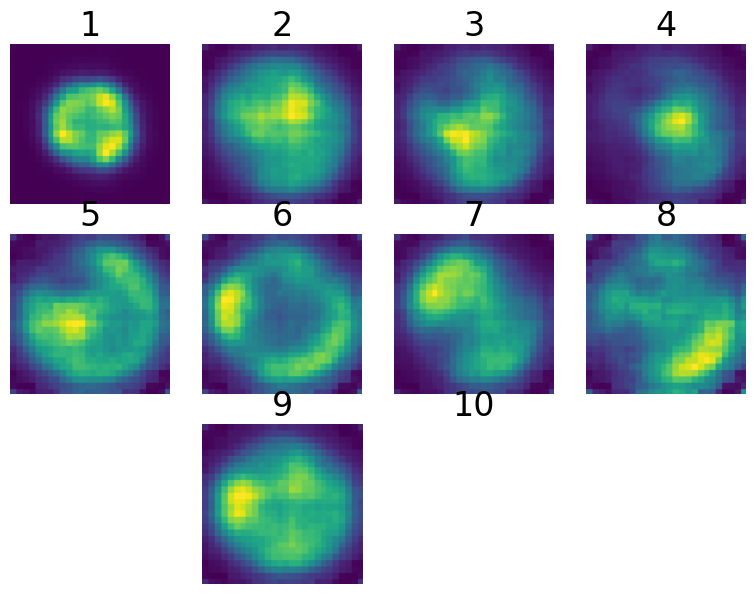

In [38]:
## Take mean of all cluster contents
## Take a cell that has a gene in every cluster and plot it:
%matplotlib inline
nr_leiden_clusters = adata.obs[f"leiden_igraph_res_{res}"].nunique()
fig, axs = create_custom_grid(nr_leiden_clusters)
for leid in range(1, nr_leiden_clusters+1):
    plotAllDataFromLeidenCluster(
        full_adata = adata,
        leiden_cluster = leid,
        ax=  axs[leid-1],
        model=subcellspace,
        leiden_key = f"leiden_igraph_res_{res}"
    )

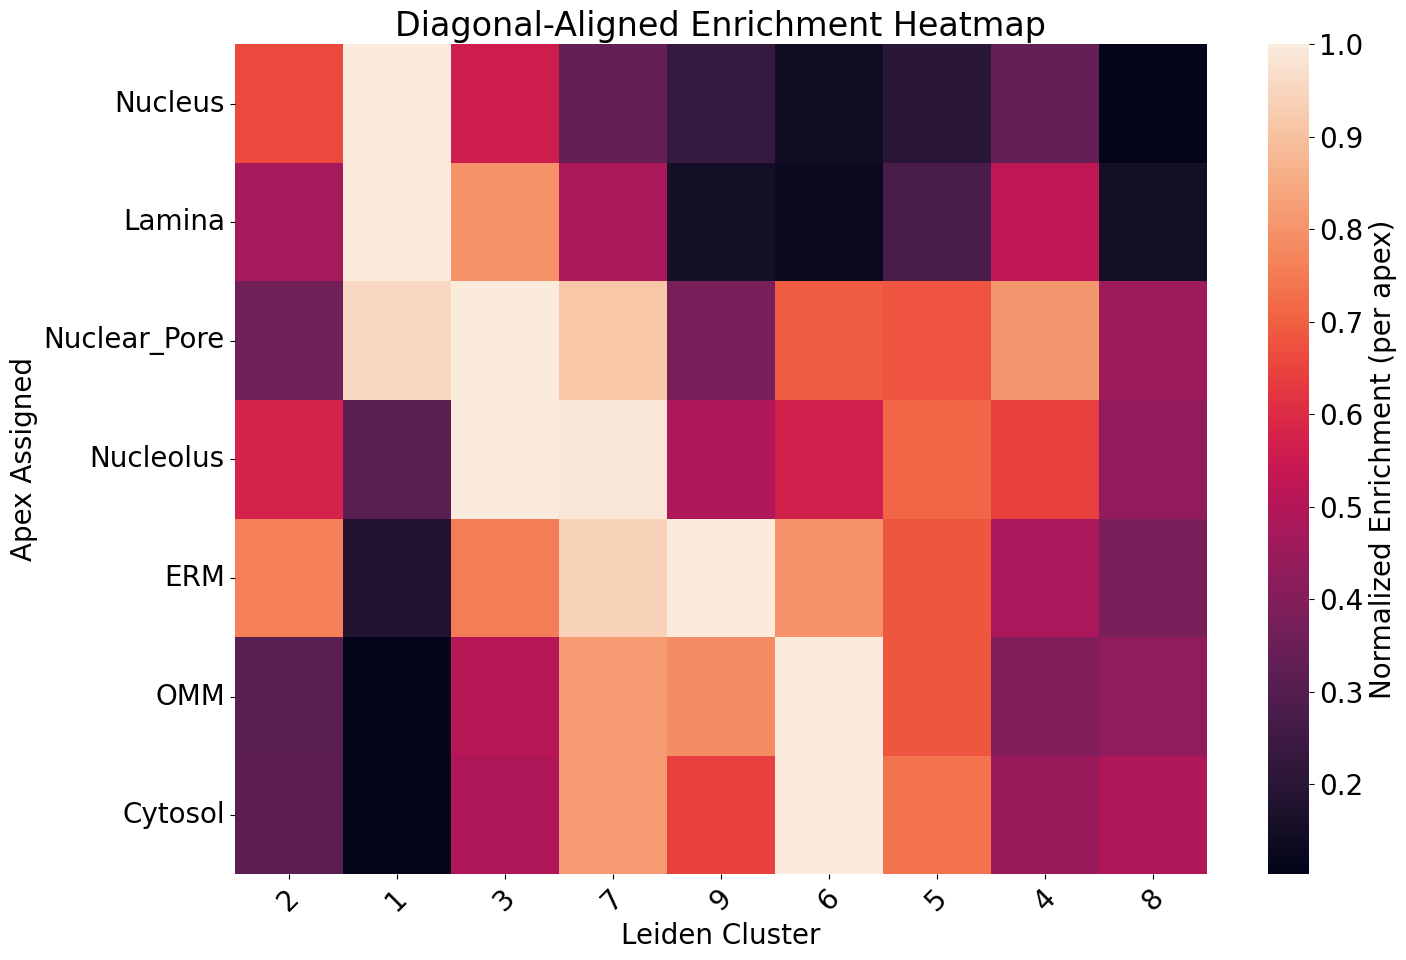

In [45]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import scipy.cluster.hierarchy as sch
import scipy.spatial.distance as ssd
from scipy.optimize import linear_sum_assignment

obs = adata[adata.obs["apex_assigned"] != "random"].obs[["apex_assigned", f'leiden_igraph_res_{res}']]

# Merge apex_assigned information from results_df
# gene_to_apex = result_df.set_index("gene_name")["apex_assigned"]
# obs = obs.assign(apex_assigned=obs["gene_name"].map(gene_to_apex))

# Aggregate counts
expression_df = pd.crosstab(obs["apex_assigned"], obs[f'leiden_igraph_res_{res}'])


# -----------------------------------------------------------
# 1️⃣ Row clustering (with optimal ordering)
# -----------------------------------------------------------
row_dist = ssd.pdist(expression_df.values, metric="euclidean")
row_linkage = sch.linkage(row_dist, method="ward")
row_linkage = sch.optimal_leaf_ordering(row_linkage, row_dist)

row_order = sch.leaves_list(row_linkage)

# Reorder rows
df_row_ordered = expression_df.iloc[row_order]

# -----------------------------------------------------------
# 2️⃣ Hungarian matching (align columns to rows)
# -----------------------------------------------------------
cost_matrix = -df_row_ordered.values  # maximize diagonal

row_ind, col_ind = linear_sum_assignment(cost_matrix)

matched_cols = list(col_ind)

# -----------------------------------------------------------
# 3️⃣ Keep ALL columns (append unmatched ones)
# -----------------------------------------------------------
all_cols = list(range(df_row_ordered.shape[1]))
unmatched_cols = [c for c in all_cols if c not in matched_cols]

# Optional: cluster unmatched columns for nicer ordering
if len(unmatched_cols) > 1:
    extra = df_row_ordered.iloc[:, unmatched_cols]
    col_dist_extra = ssd.pdist(extra.T, metric="euclidean")
    col_linkage_extra = sch.linkage(col_dist_extra, method="ward")
    col_order_extra = sch.leaves_list(col_linkage_extra)
    unmatched_cols = [unmatched_cols[i] for i in col_order_extra]

# Final column order: diagonal first, then remaining columns
col_order = matched_cols + unmatched_cols

# Apply final ordering
ordered_df = df_row_ordered.iloc[:, col_order]

# -----------------------------------------------------------
# 4️⃣ Plot heatmap
# -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(15,10))

sns.heatmap(
    ordered_df,
    robust=True,
    ax=ax,
    cbar_kws={"label": "Normalized Enrichment (per apex)"},
)

ax.set_xlabel("Leiden Cluster")
ax.set_ylabel("Apex Assigned")
ax.set_title("Diagonal-Aligned Enrichment Heatmap")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()